In [1]:
from ultralytics import YOLO
import cv2
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

In [2]:
nano_model = YOLO("yolov8n.pt")
medium_model = YOLO("yolov8m.pt")

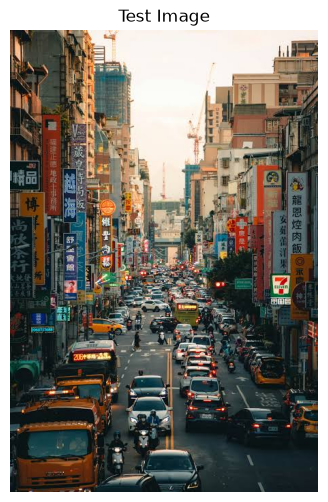

In [9]:
image_path = "../data/yolo_test/busy_city_street.jpg"

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError("Test image not found.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(image_rgb)
plt.title("Test Image")
plt.axis("off")
plt.show()

In [10]:
def run_benchmark(model, image, model_name):
    start_time = time.perf_counter()

    results = model(image, verbose=False)

    end_time = time.perf_counter()

    latency_ms = (end_time - start_time) * 1000

    result = results[0]

    detected_classes = []
    confidence_scores = []

    annotated = image.copy()

    for box in result.boxes:
        x1, y1, x2, y2 = map(
            int,
            box.xyxy[0].cpu().numpy()
        )

        confidence = float(box.conf[0])
        class_id = int(box.cls[0])

        class_name = model.names[class_id]

        detected_classes.append(class_name)
        confidence_scores.append(confidence)

        cv2.rectangle(
            annotated,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        label = f"{class_name} {confidence:.2f}"

        cv2.putText(
            annotated,
            label,
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

    class_counts = Counter(detected_classes)

    if confidence_scores:
        avg_confidence = np.mean(confidence_scores)
    else:
        avg_confidence = 0

    return {
        "model": model_name,
        "latency_ms": latency_ms,
        "class_counts": dict(class_counts),
        "avg_confidence": avg_confidence,
        "total_detections": len(detected_classes),
        "annotated_image": annotated
    }

In [11]:
nano_result = run_benchmark(
    nano_model,
    image,
    "YOLOv8n"
)

medium_result = run_benchmark(
    medium_model,
    image,
    "YOLOv8m"
)

In [12]:
print("YOLOv8n Results")
print("----------------")
print("Latency:", f"{nano_result['latency_ms']:.2f} ms")
print("Total detections:", nano_result["total_detections"])
print("Class counts:", nano_result["class_counts"])
print("Average confidence:", f"{nano_result['avg_confidence']:.3f}")

print()

print("YOLOv8m Results")
print("----------------")
print("Latency:", f"{medium_result['latency_ms']:.2f} ms")
print("Total detections:", medium_result["total_detections"])
print("Class counts:", medium_result["class_counts"])
print("Average confidence:", f"{medium_result['avg_confidence']:.3f}")

YOLOv8n Results
----------------
Latency: 50.27 ms
Total detections: 12
Class counts: {'car': 10, 'truck': 2}
Average confidence: 0.495

YOLOv8m Results
----------------
Latency: 172.71 ms
Total detections: 17
Class counts: {'car': 10, 'truck': 2, 'bus': 2, 'motorcycle': 2, 'person': 1}
Average confidence: 0.537


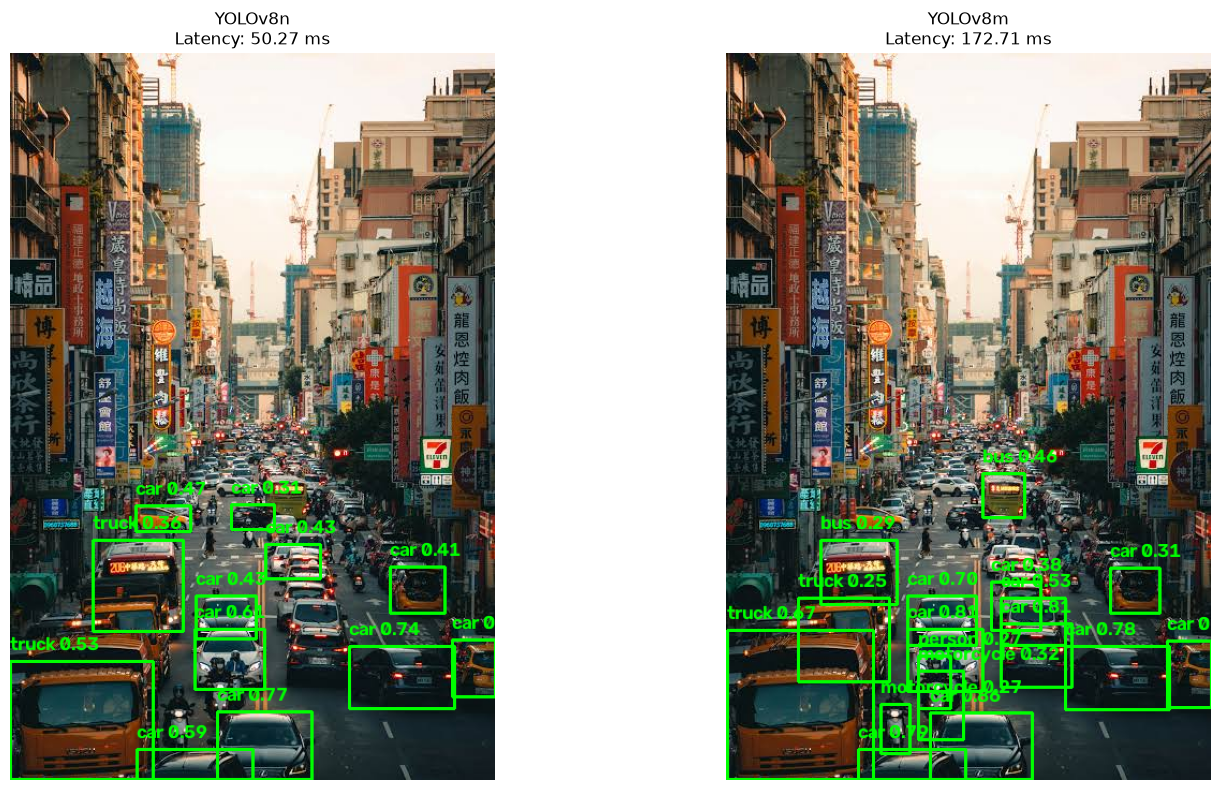

In [13]:
nano_rgb = cv2.cvtColor(
    nano_result["annotated_image"],
    cv2.COLOR_BGR2RGB
)

medium_rgb = cv2.cvtColor(
    medium_result["annotated_image"],
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
plt.imshow(nano_rgb)
plt.title(
    f"YOLOv8n\nLatency: {nano_result['latency_ms']:.2f} ms"
)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(medium_rgb)
plt.title(
    f"YOLOv8m\nLatency: {medium_result['latency_ms']:.2f} ms"
)
plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
comparison_df = pd.DataFrame({
    "Model": [
        nano_result["model"],
        medium_result["model"]
    ],

    "Inference Time (ms)": [
        nano_result["latency_ms"],
        medium_result["latency_ms"]
    ],

    "Total Detections": [
        nano_result["total_detections"],
        medium_result["total_detections"]
    ],

    "Average Confidence": [
        nano_result["avg_confidence"],
        medium_result["avg_confidence"]
    ],

    "Detected Classes": [
        str(nano_result["class_counts"]),
        str(medium_result["class_counts"])
    ]
})

comparison_df

,Model,Inference Time (ms),Total Detections,Average Confidence,Detected Classes
0,YOLOv8n,50.2691,12,0.494994,"{'car': 10, 'truck': 2}"
1,YOLOv8m,172.7143,17,0.536508,"{'car': 10, 'truck': 2, 'bus': 2, 'motorcycle'..."


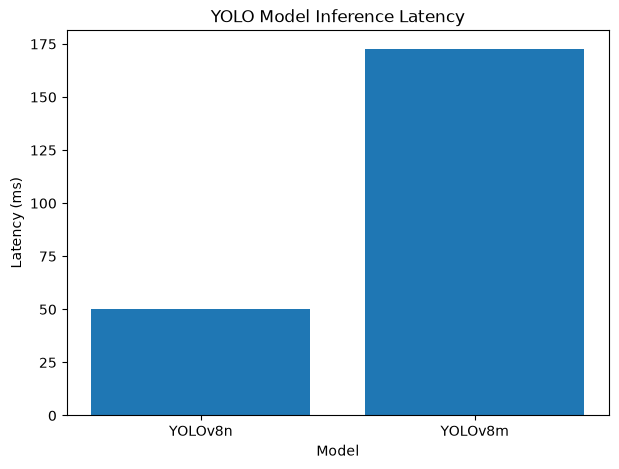

In [15]:
models = [
    nano_result["model"],
    medium_result["model"]
]

latencies = [
    nano_result["latency_ms"],
    medium_result["latency_ms"]
]

plt.figure(figsize=(7, 5))

plt.bar(models, latencies)

plt.title("YOLO Model Inference Latency")
plt.xlabel("Model")
plt.ylabel("Latency (ms)")

plt.show()